# A/B Тестирование: Проблема подглядывания

**Автор:** Прохорова Анна

**Цель:** Исследовать, как ежедневное отслеживание p-value влияет на вероятность ошибки I рода.

## 1. Моделирование А/В-теста (10 дней)

**Условия эксперимента:**
Представим, что мы заранее знаем параметры генеральных совокупностей (в реальности мы этого не знаем).
*   Тест длится 10 дней.
*   Каждый день в выборку добавляется по 100 человек.
*   Контрольная группа (μ=100, σ=20)
*   Тестовая группа (μ=105, σ=20)

**Задача:** Сгенерировать выборки с помощью `np.random.normal`, рассчитать средние значения и ежедневно проводить t-тест Стьюдента для отслеживания динамики p-value.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Параметры эксперимента
days = 10
mu_control, sigma_control, n_control = 100, 20, 100
mu_experiment, sigma_experiment, n_experiment = 105, 20, 100

np.random.seed(42)
control_means, exp_means, p_vals = [], [], []
control_cum, exp_cum = [], []

for day in range(1, days+1):
    control_day = np.random.normal(mu_control, sigma_control, n_control)
    exp_day = np.random.normal(mu_experiment, sigma_experiment, n_experiment)

    control_cum.extend(control_day)
    exp_cum.extend(exp_day)

    # Средние накопленных данных
    control_means.append(np.mean(control_cum))
    exp_means.append(np.mean(exp_cum))

    # Ежедневный t-тест
    t_stat, p_val = stats.ttest_ind(control_cum, exp_cum)
    p_vals.append(p_val)
    print(f"День {day}: p-value = {p_vals[-1]:.4f}")

День 1: p-value = 0.0047
День 2: p-value = 0.0006
День 3: p-value = 0.0003
День 4: p-value = 0.0001
День 5: p-value = 0.0003
День 6: p-value = 0.0001
День 7: p-value = 0.0001
День 8: p-value = 0.0005
День 9: p-value = 0.0003
День 10: p-value = 0.0000


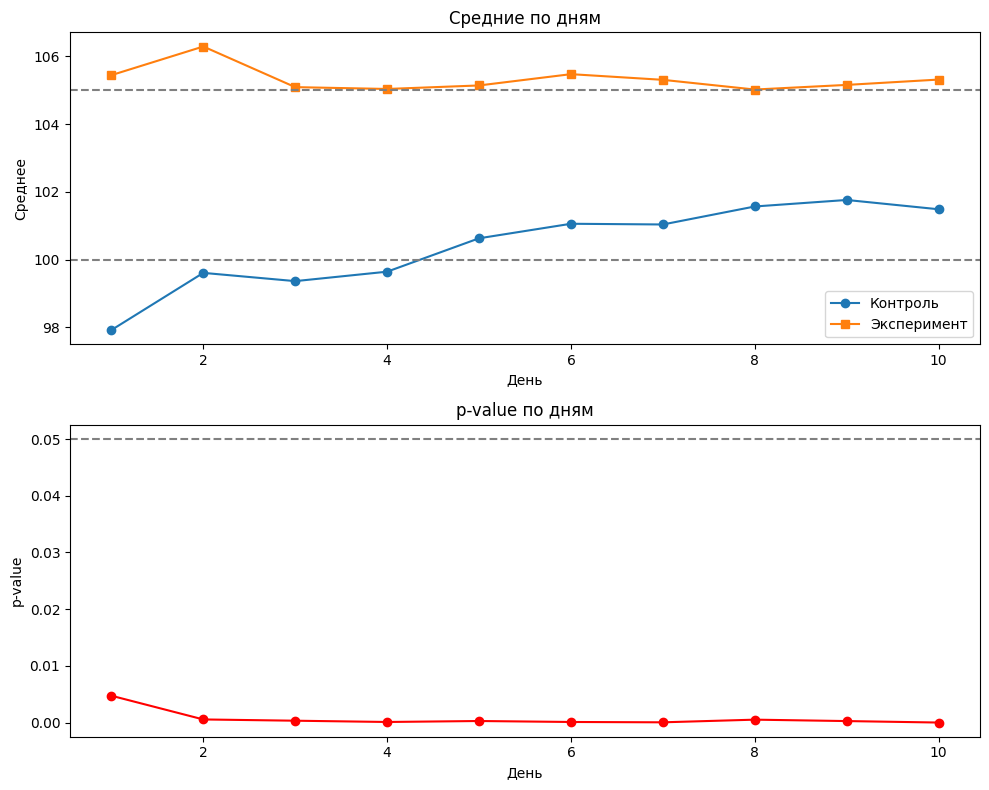

In [2]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

ax1.plot(range(1, days+1), control_means, 'o-', label='Контроль')
ax1.plot(range(1, days+1), exp_means, 's-', label='Эксперимент')
ax1.axhline(y=mu_control, color='gray', linestyle='--')
ax1.axhline(y=mu_experiment, color='gray', linestyle='--')
ax1.set_xlabel('День'), ax1.set_ylabel('Среднее'), ax1.legend(), ax1.set_title('Средние по дням')

ax2.plot(range(1, days+1), p_vals, 'r-o')
ax2.axhline(y=0.05, color='gray', linestyle='--')
ax2.set_xlabel('День'), ax2.set_ylabel('p-value'), ax2.set_title('p-value по дням')

plt.tight_layout()
plt.show()

**Вывод по 10 дням:**
p-value уже с первого дня ниже 0.05 и продолжает снижаться, оставаясь на очень низком уровне (0.0001-0.0005) все 10 дней. Это связано с тем, что изначально в генеральной совокупности заложена разница (100 против 105).

## 2. Увеличение продолжительности эксперимента (100 дней)

**Задача:** Увеличить длительность эксперимента до 100 дней и посмотреть, как изменится поведение p-value при накоплении данных.

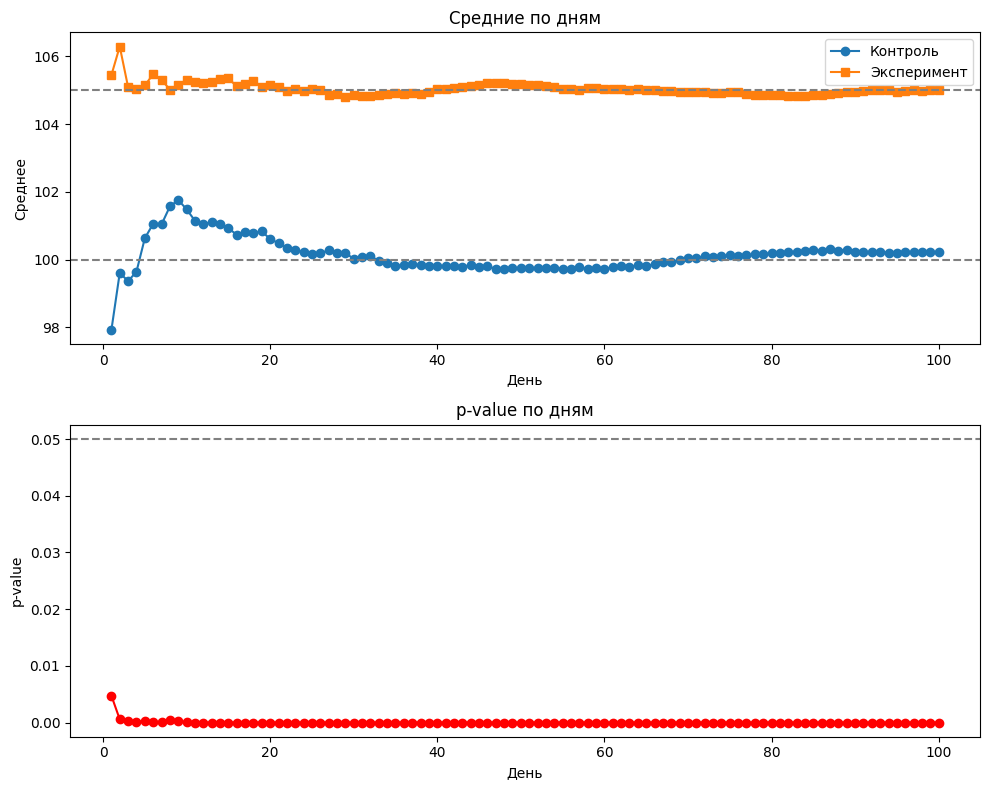

In [3]:
days = 100

np.random.seed(42)
control_means, exp_means, p_vals = [], [], []
control_cum, exp_cum = [], []

for day in range(1, days+1):
    control_day = np.random.normal(mu_control, sigma_control, n_control)
    exp_day = np.random.normal(mu_experiment, sigma_experiment, n_experiment)

    control_cum.extend(control_day)
    exp_cum.extend(exp_day)

    control_means.append(np.mean(control_cum))
    exp_means.append(np.mean(exp_cum))

    t_stat, p_val = stats.ttest_ind(control_cum, exp_cum)
    p_vals.append(p_val)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

ax1.plot(range(1, days+1), control_means, 'o-', label='Контроль')
ax1.plot(range(1, days+1), exp_means, 's-', label='Эксперимент')
ax1.axhline(y=mu_control, color='gray', linestyle='--')
ax1.axhline(y=mu_experiment, color='gray', linestyle='--')
ax1.set_xlabel('День'), ax1.set_ylabel('Среднее'), ax1.legend(), ax1.set_title('Средние по дням')

ax2.plot(range(1, days+1), p_vals, 'r-o')
ax2.axhline(y=0.05, color='gray', linestyle='--')
ax2.set_xlabel('День'), ax2.set_ylabel('p-value'), ax2.set_title('p-value по дням')

plt.tight_layout()
plt.show()

**Вывод по 100 дням:**
p-value становится еще меньше — к 100 дню стремится к нулю (≈ 0.0000).
Средние группы стабилизируются — контроль стремится к 100, эксперимент — к 105. Чем больше выборка, тем точнее тест находит реальные различия.

## 3. Эксперимент без реальных различий

**Задача:** Изменить параметры генеральных совокупностей так, чтобы различий в группах не было (обе группы μ=100). Повторить эксперимент и проверить, не найдет ли тест ложных различий.

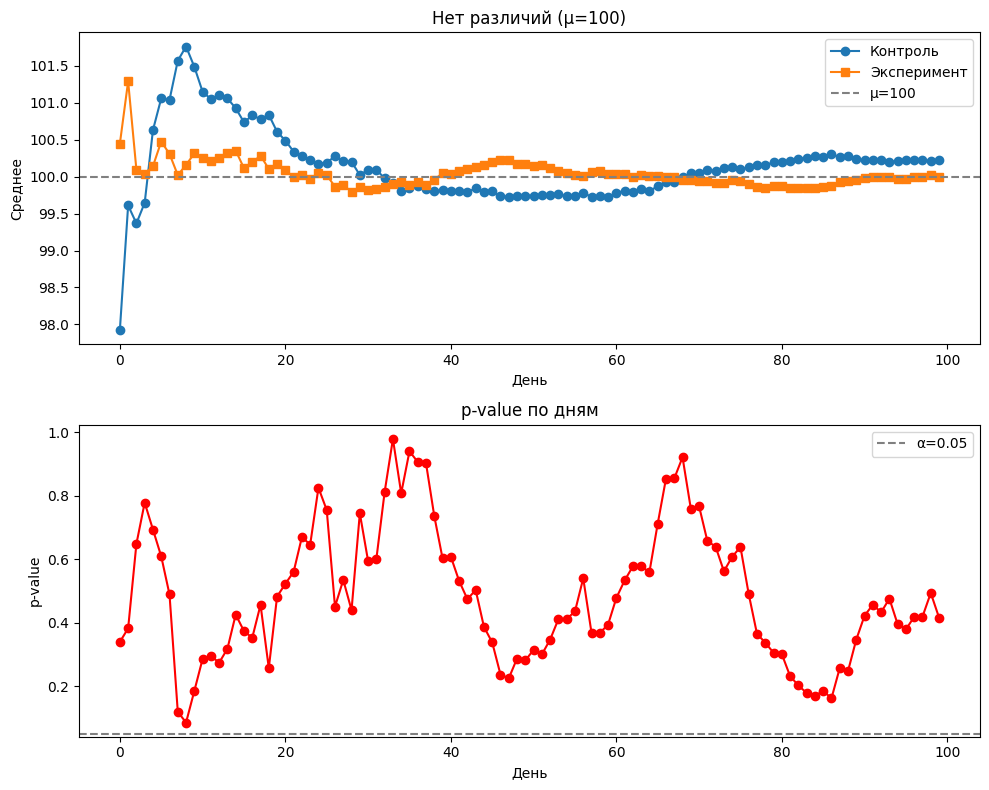

In [4]:
mu_control, mu_experiment = 100, 100

control_means, exp_means, p_vals = [], [], []
control_cum, exp_cum = [], []

np.random.seed(42)

for day in range(1, days+1):
    control_day = np.random.normal(mu_control, sigma_control, n_control)
    exp_day = np.random.normal(mu_experiment, sigma_experiment, n_experiment)

    control_cum.extend(control_day)
    exp_cum.extend(exp_day)

    control_means.append(np.mean(control_cum))
    exp_means.append(np.mean(exp_cum))
    p_vals.append(stats.ttest_ind(control_cum, exp_cum)[1])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

ax1.plot(control_means, 'o-', label='Контроль')
ax1.plot(exp_means, 's-', label='Эксперимент')
ax1.axhline(y=100, color='gray', linestyle='--', label='μ=100')
ax1.set_xlabel('День')
ax1.set_ylabel('Среднее')
ax1.legend()
ax1.set_title('Нет различий (μ=100)')

ax2.plot(p_vals, 'r-o')
ax2.axhline(y=0.05, color='gray', linestyle='--', label='α=0.05')
ax2.set_xlabel('День')
ax2.set_ylabel('p-value')
ax2.legend()
ax2.set_title('p-value по дням')

plt.tight_layout()
plt.show()

**Вывод:**
В данном эксперименте p-value всегда больше 0.05. Средние значения обеих групп колеблются вокруг 100 и примерно одинаковы. Тест не видит разницы — он правильно определяет, что группы не отличаются.

## 4. Главный вывод по работе (Проблема подглядывания)

Если останавливать эксперимент при первом достижении p-value = 0.05, это сильно завышает вероятность ложноположительного вывода (ошибка I рода вырастает с 5% до 20-30%).

**Нельзя подглядывать за результатами теста!** Размер выборки и длительность эксперимента нужно определять заранее, до его начала, чтобы избежать искажения результатов.